# Late fusion

**Summary** (dev, 241 queries, reciprocal rank fusion of finished top-1000 lists)
- **Base model: inf-retriever-v1-1.5b**, the best dense model within the 50 ms budget. The question: does adding other lists to it help?
- **Rcap@100: no.** No combination finds significantly more Exact products in the top 100 than inf-1.5B alone.
- **nDCG@10: yes.** Several combinations rank the top 10 significantly better, by up to **+2.1 points** (BM25 + inf-1.5B + arctic-m, p=0.004, 37 ms).
- **BM25 helps the ranking when combined with dense models.** On its own next to inf-1.5B the gain is not significant, but adding BM25 **raises nDCG@10 in all 63 dense sets** and lowers it in none, and it turns 3 of 4 inf-1.5B pairs from "no difference" into significantly better. It costs 1.3 ms on the CPU.
- Tuned weights never beat plain RRF; more than 3–4 systems does not help.

In [1]:
import itertools

import matplotlib.pyplot as plt
import pandas as pd

from product_search.eval.stats import paired_permutation_test
from product_search.runs import RUNS_DIR, read_json

RULE_P = 0.05
BUDGET_MS = 50
BASE = "inf15"
METRICS = {"Rcap@100_exact": "Rcap", "nDCG@10": "nDCG"}
# short name: (run, label, group)
SYSTEMS = {
    "bm25": ("bm25_default", "BM25", "word match"),
    "inf15": ("dense_inf_15b", "inf-1.5B", "LLM"),
    "arcticm": ("dense_arctic_m", "arctic-m", "encoder"),
    "arcticl": ("dense_arctic_l", "arctic-l", "encoder"),
    "mxbai": ("dense_mxbai_large", "mxbai", "encoder"),
    "bgel": ("dense_bge_large", "bge-large", "encoder"),
    "pplx4": ("dense_pplx_4b", "pplx-4B", "LLM"),
}
COLOURS = {"encoder": "#2a78d6", "LLM": "#eb6834", "word match": "#888780"}
GREEN, RED = "#d6f0d6", "#f7d4d4"
DOT = {"better": "#0ca30c", "worse": "#d03b3b", "none": "#888780"}
FUSION_DIR = RUNS_DIR / "fusion"

single = {
    short: pd.read_parquet(RUNS_DIR / run / "metrics_per_query_dev.parquet")
    for short, (run, *_) in SYSTEMS.items()
}
single_p99 = {
    short: read_json(RUNS_DIR / run / "meta.json")["cost"]["latency"]["p99_ms"]
    for short, (run, *_) in SYSTEMS.items()
}
rrf_rows = pd.read_csv(FUSION_DIR / "rrf.csv").set_index("combination")
rrf_tables = pd.read_parquet(FUSION_DIR / "rrf_per_query.parquet").set_index("query_id")


def name(combo: str) -> str:
    """Readable name of a system or combination."""
    return " + ".join(SYSTEMS[s][1] for s in combo.split("+"))


def per_query(combo: str) -> pd.DataFrame:
    """Per-query metrics of one system or one RRF combination."""
    if "+" not in combo:
        return single[combo]
    return rrf_tables[rrf_tables["combination"] == combo]


def mean(combo: str, metric: str) -> float:
    return float(per_query(combo)[metric].mean())


def p99(combo: str) -> float:
    return single_p99[combo] if "+" not in combo else float(rrf_rows.loc[combo, "p99_ms"])


def compare(a: str, b: str, metric: str) -> tuple[float, float]:
    """Difference b - a in points and permutation-test p-value."""
    diff, p = paired_permutation_test(per_query(a)[metric], per_query(b)[metric])
    return round(diff * 100, 1), round(p, 3)


def p_text(p: float) -> str:
    return "p<0.001" if p < 0.001 else f"p={p:.3f}"


def verdict(diff: float, p: float) -> str:
    if p >= RULE_P:
        return "none"
    return "better" if diff > 0 else "worse"


def significance_colours(row: pd.Series) -> list[str]:
    """Green on a Δ/p pair when significantly better, red when significantly worse."""
    styles = pd.Series("", index=row.index)
    for column in row.index:
        if column.startswith("p ") and pd.notna(row[column]) and row[column] < RULE_P:
            delta = "Δ " + column[2:]
            styles[[delta, column]] = f"background-color: {GREEN if row[delta] > 0 else RED}"
    return styles.tolist()


def budget_style(ms: float) -> str:
    return f"background-color: {GREEN if ms <= BUDGET_MS else RED}"


def number_formats(table: pd.DataFrame) -> dict[str, str]:
    return {
        c: "{:.3f}" if c.startswith(("p ", "Rcap@", "nDCG@")) else "{:.1f}"
        for c in table.select_dtypes("float").columns
    }


combos = list(rrf_rows.index)
in_budget = [c for c in combos if p99(c) <= BUDGET_MS]

## 1. Setup

**Late fusion** merges the finished ranked lists of several systems into one. Each system's saved top 1,000 per query is combined with **reciprocal rank fusion (RRF)**: a product gets 1 / (60 + rank) from every list it appears in, and the sums are re-sorted. RRF uses ranks only, so scores on different scales need no tuning.

**Members:** BM25 plus the 6 dense models that were significantly better than BM25 and within the **50 ms p99 budget** (notebook 04). All **120 combinations** of 2 or more were scored; **34 are within budget**. Latency of a combination: BM25 runs on the CPU next to the GPU, dense models run one after another, so p99 = max(BM25, sum of dense p99s).

**Comparison:** every combination against **inf-1.5B alone**, the model we would use anyway. A combination is only worth its extra cost if it beats that.

In [2]:
members = pd.DataFrame(
    {
        SYSTEMS[s][1]: {
            "group": SYSTEMS[s][2],
            "Rcap@100": mean(s, "Rcap@100_exact"),
            "nDCG@10": mean(s, "nDCG@10"),
            "p99 (ms)": p99(s),
        }
        for s in SYSTEMS
    }
).T
display(
    members.style.map(lambda g: f"color: {COLOURS[g]}; font-weight: bold", subset=["group"])
    .map(budget_style, subset=["p99 (ms)"])
    .format({"Rcap@100": "{:.3f}", "nDCG@10": "{:.3f}", "p99 (ms)": "{:.1f}"})
)

,group,Rcap@100,nDCG@10,p99 (ms)
BM25,word match,0.706,0.691,1.3
inf-1.5B,LLM,0.765,0.759,27.6
arctic-m,encoder,0.736,0.750,9.7
arctic-l,encoder,0.718,0.743,15.1
mxbai,encoder,0.720,0.732,13.9
bge-large,encoder,0.718,0.725,14.2
pplx-4B,LLM,0.726,0.739,48.0


**Table 1. The 7 members on their own.** *Group* in its colour (encoder blue, LLM orange, BM25 grey). *p99*: 99% of queries are faster than this; green = within the 50 ms budget. inf-1.5B is best on both metrics.

## 2. Does any combination beat inf-1.5B?

In [3]:
rows = []
for combo in [c for c in in_budget if BASE in c.split("+")]:
    row = {"combination": name(combo), "p99 (ms)": p99(combo)}
    for metric, short in METRICS.items():
        diff, p = compare(BASE, combo, metric)
        row |= {metric.split("_")[0]: mean(combo, metric), f"Δ {short}": diff, f"p {short}": p}
    rows.append(row)
with_base = pd.DataFrame(rows).sort_values("Δ nDCG", ascending=False).set_index("combination")
display(
    with_base.style.apply(significance_colours, axis=1)
    .map(budget_style, subset=["p99 (ms)"])
    .format(number_formats(with_base))
)

,p99 (ms),Rcap@100,Δ Rcap,p Rcap,nDCG@10,Δ nDCG,p nDCG
combination,,,,,,,
BM25 + inf-1.5B + arctic-m,37.4,0.775,1.0,0.297,0.780,2.1,0.004
BM25 + inf-1.5B + arctic-l,42.7,0.769,0.4,0.656,0.776,1.7,0.024
BM25 + inf-1.5B + mxbai,41.5,0.777,1.3,0.187,0.776,1.7,0.021
BM25 + inf-1.5B + bge-large,41.8,0.778,1.3,0.163,0.775,1.6,0.040
inf-1.5B + arctic-m,37.4,0.766,0.1,0.913,0.774,1.4,0.006
BM25 + inf-1.5B,27.6,0.770,0.5,0.619,0.772,1.3,0.125
inf-1.5B + mxbai,41.5,0.770,0.6,0.202,0.768,0.9,0.140
inf-1.5B + arctic-l,42.7,0.761,-0.4,0.603,0.765,0.6,0.260
inf-1.5B + bge-large,41.8,0.768,0.4,0.448,0.763,0.3,0.571


**Table 2. Every within-budget combination that contains inf-1.5B, against inf-1.5B alone** (Rcap@100 0.765, nDCG@10 0.759). *Δ*: combination minus inf-1.5B in points (0.01 = 1 point). *p*: paired permutation test. **Green: significantly better (p < 0.05); red: significantly worse; no colour: no significant difference.** Sorted by Δ nDCG. **Rcap@100 never improves significantly; nDCG@10 does in 5 of 9, and 4 of those 5 include BM25.**

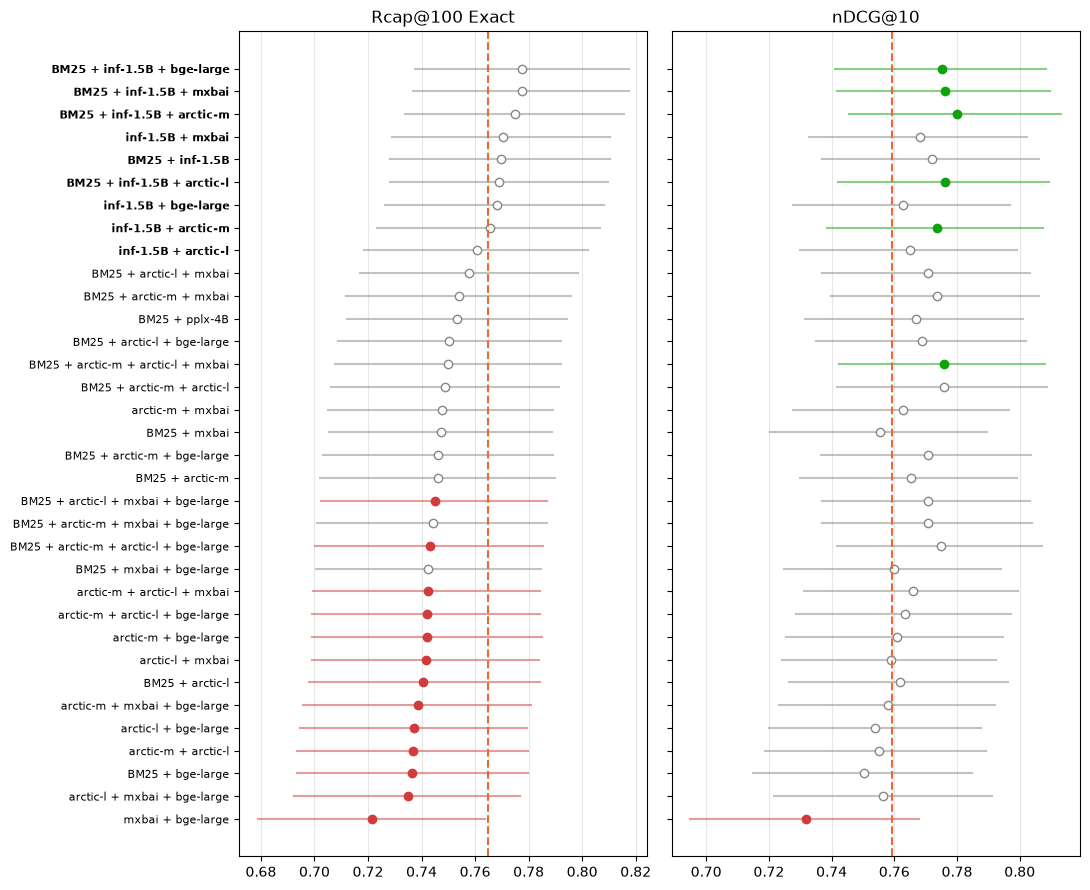

In [4]:
order = sorted(in_budget, key=lambda c: rrf_rows.loc[c, "Rcap@100_exact"])
fig, axes = plt.subplots(1, 2, figsize=(11, 9), sharey=True)
for ax, metric in zip(axes, METRICS, strict=True):
    for y, combo in enumerate(order):
        r = rrf_rows.loc[combo]
        colour = DOT[verdict(r[f"Δ {metric} vs inf15"], r[f"p {metric} vs inf15"])]
        filled = colour != DOT["none"]
        ax.plot([r[f"{metric}_low"], r[f"{metric}_high"]], [y, y], color=colour, alpha=0.5)
        ax.plot(r[metric], y, "o", color=colour, markerfacecolor=colour if filled else "white")
    ax.axvline(mean(BASE, metric), color="#eb6834", linestyle="--")
    ax.set(title=metric.replace("_exact", " Exact"))
    ax.grid(axis="x", alpha=0.3)
axes[0].set_yticks(range(len(order)), [name(c) for c in order], fontsize=8)
for tick, combo in zip(axes[0].get_yticklabels(), order, strict=True):
    if BASE in combo.split("+"):
        tick.set_fontweight("bold")
plt.tight_layout()

**Figure 1. All 34 within-budget combinations against inf-1.5B.** Dot = mean, line = 95% bootstrap interval. Orange dashed line: inf-1.5B alone. **Green filled: significantly better than inf-1.5B; red filled: significantly worse; grey hollow: no significant difference.** Bold names contain inf-1.5B. Sorted by Rcap@100. Left: nothing is green, and most combinations without inf-1.5B are significantly worse. Right: 5 combinations with inf-1.5B turn green, plus one 4-model encoder set with BM25.

## 3. Does BM25 help?

Same dense set with and without BM25. First for inf-1.5B and its within-budget partners, then for all 63 dense sets.

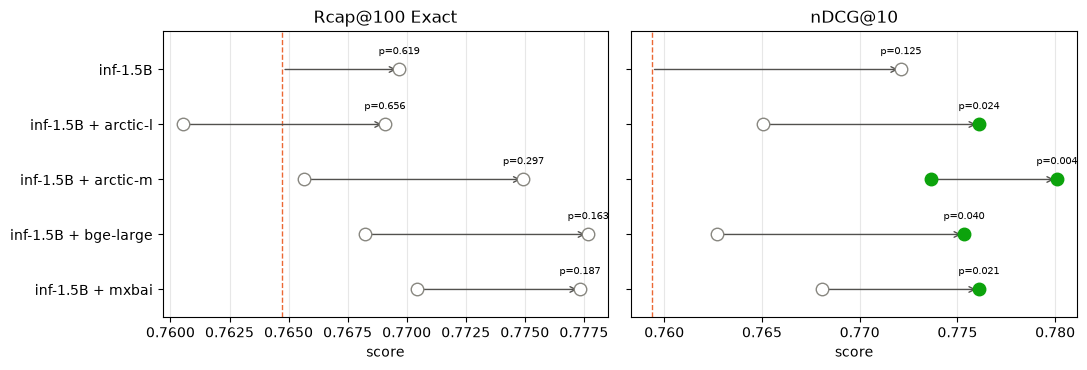

In [5]:
partners = [c[len("bm25+") :] for c in in_budget if c.startswith(f"bm25+{BASE}+")]
dense_rows = [BASE, *sorted(partners, key=name)]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, metric in zip(axes, METRICS, strict=True):
    ax.axvline(mean(BASE, metric), color="#eb6834", linestyle="--", linewidth=1)
    for y, dense in enumerate(dense_rows):
        without, with_bm25 = dense, f"bm25+{dense}"
        x0, x1 = mean(without, metric), mean(with_bm25, metric)
        ax.annotate(
            "", xy=(x1, y), xytext=(x0, y), arrowprops={"arrowstyle": "->", "color": "#52514e"}
        )
        for combo, x in [(without, x0), (with_bm25, x1)]:
            if combo == BASE:
                continue
            colour = DOT[verdict(*compare(BASE, combo, metric))]
            face = colour if colour != DOT["none"] else "white"
            ax.plot(x, y, "o", color=colour, markerfacecolor=face, markersize=9, zorder=3)
        ax.text(x1, y - 0.28, p_text(compare(BASE, with_bm25, metric)[1]), fontsize=7, ha="center")
    ax.set(title=metric.replace("_exact", " Exact"), xlabel="score")
    ax.grid(axis="x", alpha=0.3)
axes[0].set_yticks(range(len(dense_rows)), [name(d) for d in dense_rows])
axes[0].set_ylim(len(dense_rows) - 0.5, -0.7)
plt.tight_layout()

**Figure 2. What adding BM25 does next to inf-1.5B.** One row per dense set. **Arrow: from the set without BM25 (tail) to the same set with BM25 (head).** Orange dashed line: inf-1.5B alone. **Green filled: significantly better than inf-1.5B alone (p < 0.05); grey hollow: no significant difference.** p above each arrowhead: the set with BM25 against inf-1.5B. Every arrow points right, so BM25 always adds a little; x-axes are zoomed, and each arrow is about 1 point. **nDCG@10 (right): BM25 turns 3 grey sets green.** Rcap@100 (left): nothing turns green.

In [6]:
dense_names = [s for s in SYSTEMS if s != "bm25"]
dense_sets = [
    "+".join(c)
    for k in range(1, len(dense_names) + 1)
    for c in itertools.combinations(dense_names, k)
]
effect = []
for dense in dense_sets:
    for metric, short in METRICS.items():
        diff, p = compare(dense, f"bm25+{dense}", metric)
        effect.append(
            {
                "dense set": dense,
                "has inf-1.5B": BASE in dense.split("+"),
                "dense models": dense.count("+") + 1,
                "metric": short,
                "Δ": diff,
                "p": p,
            }
        )
effect = pd.DataFrame(effect)
effect["raised"] = effect["Δ"] > 0
effect["significantly better"] = (effect["p"] < RULE_P) & (effect["Δ"] > 0)
effect["significantly worse"] = (effect["p"] < RULE_P) & (effect["Δ"] < 0)
COUNTS = ["raised", "significantly better", "significantly worse"]


def summarise(groups: "pd.core.groupby.DataFrameGroupBy") -> pd.DataFrame:
    """Number of sets, counts per outcome and mean change."""
    table = groups[COUNTS].sum().astype(int)
    sets = groups.size().rename("sets").to_frame()
    return sets.join(table).assign(**{"mean Δ": groups["Δ"].mean()})


print(summarise(effect.groupby("metric")).round(1).to_string())
by_size = summarise(effect.groupby(["metric", "dense models"]))
display(
    by_size.loc[["nDCG", "Rcap"]]
    .style.map(
        lambda v: f"background-color: {GREEN}" if v > 0 else "", subset=["significantly better"]
    )
    .map(lambda v: f"background-color: {RED}" if v > 0 else "", subset=["significantly worse"])
    .format({"mean Δ": "{:+.1f}"})
)

        sets  raised  significantly better  significantly worse  mean Δ
metric                                                                 
Rcap      63      56                    16                    0     0.8
nDCG      63      63                    27                    0     1.0


**Table 3. Adding BM25 to every dense set** (63 sets of the 6 dense models, latency ignored), grouped by how many dense models are in the set. *Raised*: sets where BM25 increased the score at all. *Significantly better / worse*: p < 0.05 for set + BM25 against the set alone; green / red when non-zero. *Mean Δ*: average change in points. Totals above the table. **BM25 never makes a set significantly worse, and raises nDCG@10 in every set.** Its help shrinks as dense models are added. The sets share models, so the 63 are not independent tests.

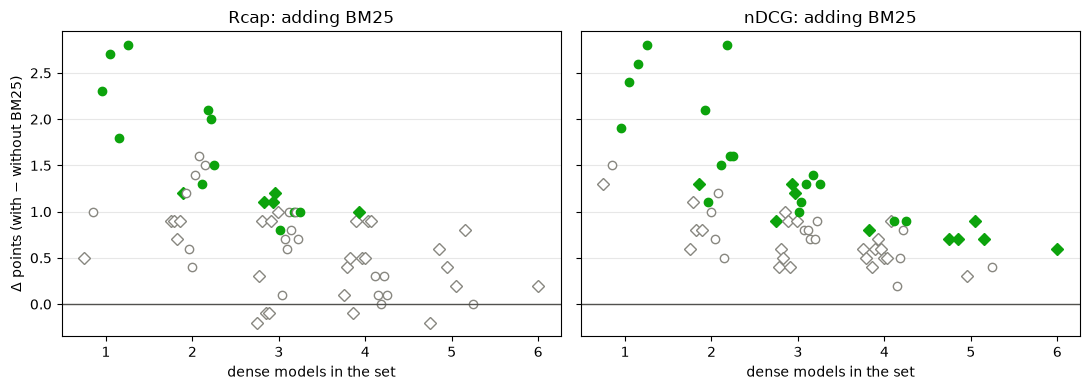

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, short in zip(axes, METRICS.values(), strict=True):
    rows = effect[effect["metric"] == short]
    for k, group in rows.groupby("dense models"):
        offsets = (
            [0.0] if len(group) == 1 else [i / (len(group) - 1) - 0.5 for i in range(len(group))]
        )
        for offset, (_, r) in zip(offsets, group.iterrows(), strict=True):
            colour = DOT[verdict(r["Δ"], r["p"])]
            filled = colour != DOT["none"]
            ax.plot(
                k + 0.5 * offset,
                r["Δ"],
                "D" if r["has inf-1.5B"] else "o",
                color=colour,
                markerfacecolor=colour if filled else "white",
                markersize=6,
            )
    ax.axhline(0, color="#52514e", linewidth=1)
    ax.set(title=f"{short}: adding BM25", xlabel="dense models in the set")
    ax.set_xticks(range(1, 7))
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Δ points (with − without BM25)")
plt.tight_layout()

**Figure 3. The effect of adding BM25, one marker per dense set.** y: score with BM25 minus score without, in points; above the black line = BM25 helped. **Green filled: significantly better with BM25; grey hollow: no significant difference** (no set got significantly worse). Diamond: set contains inf-1.5B; circle: it doesn't. Right: every marker sits above zero.

## 4. More systems, tuned weights

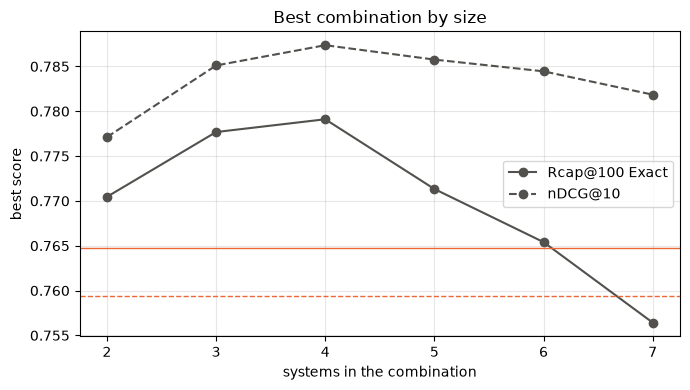

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
for metric, style in zip(METRICS, ["-", "--"], strict=True):
    best = rrf_rows.groupby("systems")[metric].max()
    ax.plot(
        best.index,
        best.values,
        marker="o",
        linestyle=style,
        color="#52514e",
        label=metric.replace("_exact", " Exact"),
    )
    ax.axhline(mean(BASE, metric), color="#eb6834", linestyle=style, linewidth=1)
ax.set(xlabel="systems in the combination", ylabel="best score", title="Best combination by size")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()

**Figure 4. Best score at each combination size**, all 120 combinations, latency ignored. Grey: best combination of that size (solid Rcap@100, dashed nDCG@10). Orange: inf-1.5B alone. **The best score peaks at 3–4 systems, then falls**: adding weaker lists starts to dilute the strong ones. **The 3–4 peak is not a reason to add systems:** every 4-system combination with inf-1.5B is over the 50 ms budget, and none of the larger ones is significantly better than the pick (Table 4). Part of the peak is also selection: the best of 35 combinations of one size looks high by chance.

In [9]:
PICK = "bm25+inf15+arcticm"
larger = {rrf_rows[rrf_rows["systems"] == k][metric].idxmax() for k in [4, 5] for metric in METRICS}
rows = []
for combo in [PICK, *sorted(larger, key=lambda c: (rrf_rows.loc[c, "systems"], c))]:
    row = {"combination": name(combo), "p99 (ms)": p99(combo)}
    for metric, short in METRICS.items():
        row[metric.split("_")[0]] = mean(combo, metric)
        if combo != PICK:
            row[f"Δ {short}"], row[f"p {short}"] = compare(PICK, combo, metric)
    rows.append(row)
against_pick = pd.DataFrame(rows).set_index("combination")
display(
    against_pick.style.apply(significance_colours, axis=1)
    .map(budget_style, subset=["p99 (ms)"])
    .format(number_formats(against_pick), na_rep="–")
)

,p99 (ms),Rcap@100,nDCG@10,Δ Rcap,p Rcap,Δ nDCG,p nDCG
combination,,,,,,,
BM25 + inf-1.5B + arctic-m,37.4,0.775,0.780,–,–,–,–
BM25 + inf-1.5B + mxbai + pplx-4B,89.5,0.779,0.787,0.4,0.331,0.7,0.196
BM25 + inf-1.5B + arctic-m + mxbai + pplx-4B,99.2,0.771,0.786,-0.4,0.657,0.6,0.254


**Table 4. The best larger combinations against the pick, BM25 + inf-1.5B + arctic-m.** The best 4- and 5-system combinations on each metric. *Δ*: combination minus the pick, in points; *p*: paired permutation test. Green/red: significantly better / worse than the pick; p99 green within the 50 ms budget. **All are over budget and none is significantly better**: twice the latency for no clear gain.

In [10]:
weighted = pd.read_csv(FUSION_DIR / "weighted.csv")
rows = []
for combo, group in weighted.groupby("combination", sort=False):
    top = group.sort_values("Rcap@100_exact", ascending=False).iloc[0]
    better = (
        (group["p Rcap@100_exact vs rrf"] < RULE_P) & (group["Δ Rcap@100_exact vs rrf"] > 0)
    ) | ((group["p nDCG@10 vs rrf"] < RULE_P) & (group["Δ nDCG@10 vs rrf"] > 0))
    rows.append(
        {
            "combination": name(combo),
            "weights tried": len(group),
            "best weights": top["weights"],
            "Δ Rcap": top["Δ Rcap@100_exact vs rrf"],
            "p Rcap": top["p Rcap@100_exact vs rrf"],
            "Δ nDCG": top["Δ nDCG@10 vs rrf"],
            "p nDCG": top["p nDCG@10 vs rrf"],
            "settings better than RRF": int(better.sum()),
        }
    )
tuned = pd.DataFrame(rows).set_index("combination")
display(tuned.style.apply(significance_colours, axis=1).format(number_formats(tuned)))

,weights tried,best weights,Δ Rcap,p Rcap,Δ nDCG,p nDCG,settings better than RRF
combination,,,,,,,
BM25 + inf-1.5B + mxbai,36,0.2 0.5 0.3,0.6,0.486,-0.1,0.867,0
BM25 + inf-1.5B + bge-large,36,0.2 0.5 0.3,0.2,0.691,0.1,0.896,0
BM25 + inf-1.5B,9,0.2 0.8,0.3,0.743,-0.0,0.942,0
BM25 + inf-1.5B + arctic-m,36,0.3 0.6 0.1,-0.4,0.683,-0.5,0.269,0


**Table 5. Weighted sum against RRF** for the 3 best within-budget combinations and the best BM25 pair. Weighted sum: each list's scores scaled to 0–1 per query, then summed with weights in steps of 0.1 (in the order of the names). *Best weights*: the setting with the highest Rcap@100; *Δ, p*: that setting against RRF of the same systems. *Settings better than RRF*: how many of the tried settings were significantly better on either metric. **None of 117 settings beat RRF**, so RRF stays: no weights to choose, nothing to overfit.

## 5. Takeaways

| Question | Answer |
|---|---|
| Does fusion find more Exact products in the top 100? | **No.** Nothing beats inf-1.5B on Rcap@100. |
| Does fusion rank the top 10 better? | **Yes**, up to +2.1 points nDCG@10. |
| Does BM25 help? | **In combination, yes, for ranking**: +1 nDCG@10 in every dense set, never worse, 1.3 ms on the CPU. Not for Rcap@100 next to inf-1.5B. |
| Weighted or RRF? | **RRF.** Tuned weights never beat it. |
| How many systems? | **3**, at most 4. |
| Does combining help weaker models? | **Yes, but not enough.** Combinations without inf-1.5B often beat each of their members, but never reach inf-1.5B on Rcap@100. |

**Rule for choosing:** the cheapest combination that is significantly better than inf-1.5B and within budget; add a system only if the larger combination is significantly better than that pick and still within budget. Nothing larger passes.

**Candidate first stage: BM25 + inf-1.5B + arctic-m** (Rcap@100 0.775, nDCG@10 0.780, p99 37 ms). Simplest fallback: inf-1.5B alone.

**Open:** the gain is in the top-10 order, and a reranker will re-sort the top 100 anyway. Once a reranker exists, re-test whether fusion still adds anything on top of it. The test set is used once, for the final system.